### Import Statments, load csv

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import skew
import json
import cv2
import numpy as np


# raw json data from ocr
json_fp = r"..\results\ocr_all_results.json"

# sample images
image_dir = Path(r"..\sample_images")

# csv file with ocr results
csv_file = r"..\results\ocr_evaluation_detail.csv"

# read in csv data
df = pd.read_csv(csv_file)

### Aggregate Summary Stats

In [2]:
#create labels for ocr models
df["Model"] = df["profile"].map({"baseline": "EasyOCR","large": "Florence-2"})

# group by model
summary_group = df.groupby("Model")

# create stats for each model type
summary = summary_group.agg(
    Samples=("image", "count"),
    Mean_CER=("normalized_cer", "mean"),
    Exact_Match_Rate=("exact_match_normalized", "mean"),
    Mean_Runtime=("analysis_seconds", "mean")
    )

summary.reset_index()
print("\n OCR Model Summary \n")
print(summary)


 OCR Model Summary 

            Samples  Mean_CER  Exact_Match_Rate  Mean_Runtime
Model                                                        
EasyOCR         134  0.218036          0.373134      0.899471
Florence-2      134  0.053673          0.671642      8.902323


### Summary Statistics

In [3]:
print("\n OCR Model Summary Florence-2\n")
print(df[df["Model"] == "Florence-2"]["normalized_cer"].describe())

print("\n OCR Model Summary EasyOCR \n")
print(df[df["Model"] == "EasyOCR"]["normalized_cer"].describe())


 OCR Model Summary Florence-2

count    134.000000
mean       0.053673
std        0.137704
min        0.000000
25%        0.000000
50%        0.000000
75%        0.068992
max        1.375000
Name: normalized_cer, dtype: float64

 OCR Model Summary EasyOCR 

count    134.000000
mean       0.218036
std        0.290358
min        0.000000
25%        0.000000
50%        0.076255
75%        0.393750
max        1.000000
Name: normalized_cer, dtype: float64


### Summary Plots of Model Performace

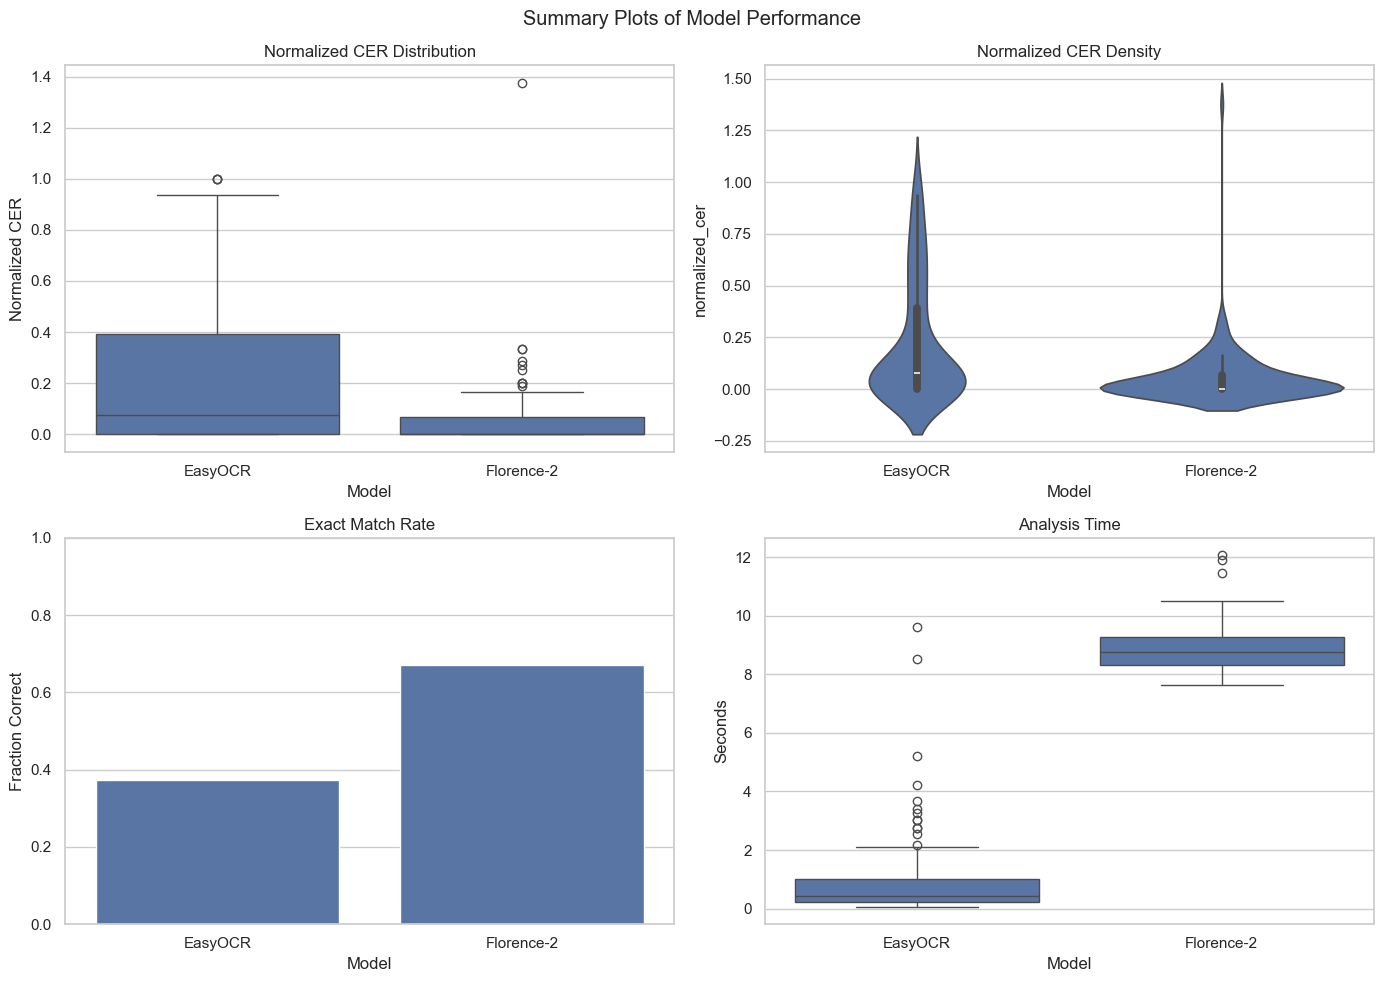

In [4]:
# set up seaborn/matplotlib plot
sns.set_theme(style="whitegrid", palette="deep")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Summary Plots of Model Performance")

# add box plot
sns.boxplot(data=df,x="Model",y="normalized_cer",ax=axes[0, 0])

# format axis
axes[0, 0].set_title("Normalized CER Distribution")
axes[0, 0].set_ylabel("Normalized CER")

# add violin plot
sns.violinplot(data=df,x="Model",y="normalized_cer",ax=axes[0, 1])

# format axis
axes[0, 1].set_title("Normalized CER Density")

# determine exact match rate for each model
exact_match = df.groupby("Model")["exact_match_normalized"].mean().reset_index()

# create bar plot with exact matches
sns.barplot(data=exact_match,x="Model",y="exact_match_normalized",ax=axes[1, 0])

# format axis
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title("Exact Match Rate")
axes[1, 0].set_ylabel("Fraction Correct")

# create box plot with analysis time by model
sns.boxplot(data=df,x="Model",y="analysis_seconds",ax=axes[1, 1])

# format axis
axes[1, 1].set_title("Analysis Time")
axes[1, 1].set_ylabel("Seconds")

# plot and save figure
plt.tight_layout()
plt.savefig(r".\images\ocr_model_comparison.png", dpi=600)
plt.show()

### Comparison of Stats Grouped by Category and Model


=== Category Performance ===

                       Mean_CER  Exact_Match
category   Model                            
Engrave    EasyOCR     0.257541     0.323077
           Florence-2  0.065751     0.692308
Laser Mark EasyOCR     0.180821     0.420290
           Florence-2  0.042296     0.652174


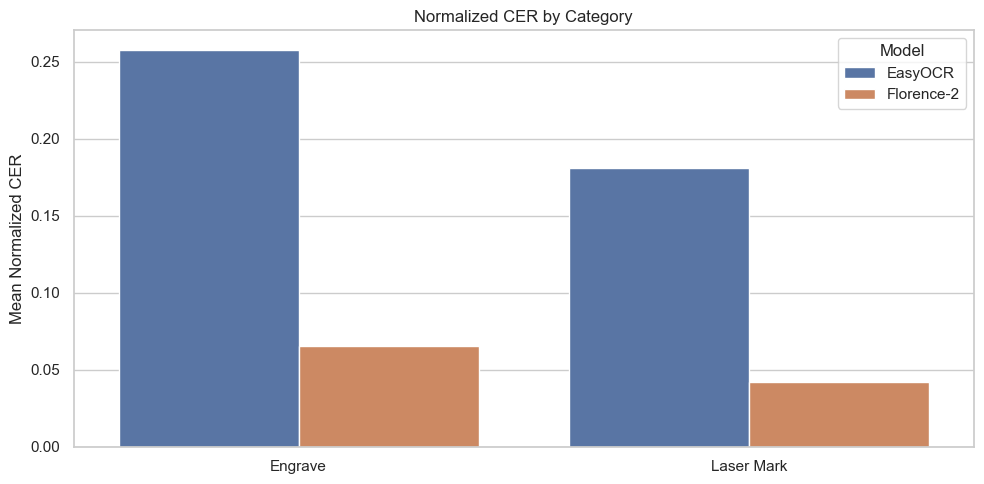

In [5]:
# group by image category and model
cat_group = df.groupby(["category", "Model"])

# create mean CER and exact match stats for groups
category_stats = cat_group.agg(
    Mean_CER=("normalized_cer", "mean"),
    Exact_Match=("exact_match_normalized", "mean")
    )

category_stats.reset_index()

print("\n=== Category Performance ===\n")
print(category_stats)

# create figure
plt.figure(figsize=(10, 5))

# add barplot with category stats
sns.barplot(data=category_stats,x="category",y="Mean_CER",hue="Model")

# format plot
plt.title("Normalized CER by Category")
plt.ylabel("Mean Normalized CER")
plt.xlabel("")
plt.tight_layout()

# save and show plot
plt.savefig(r".\images\ocr_category_cer.png", dpi=600)
plt.show()

###  Empirical Cumulative Distribution Function (ECDF) Plot

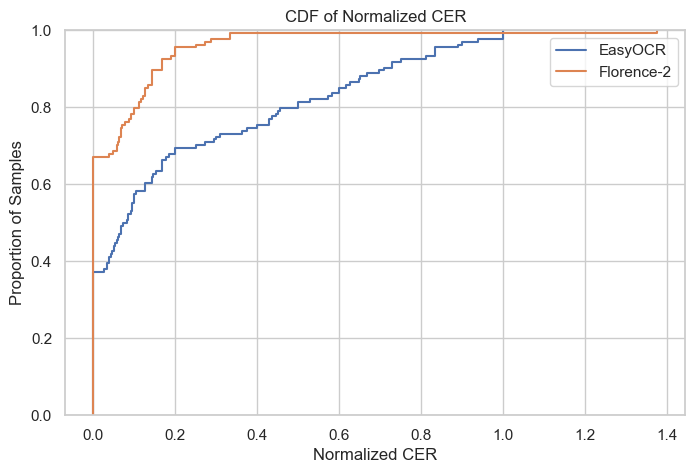

In [6]:
# create figure
plt.figure(figsize=(8,5))

# create ECDF plot for models
for model in ["EasyOCR", "Florence-2"]:

    sns.ecdfplot(
        data=df[df["Model"] == model],
        x="normalized_cer",
        label=model
        )

# format plot
plt.legend()
plt.title("CDF of Normalized CER")
plt.xlabel("Normalized CER")
plt.ylabel("Proportion of Samples")

# save figure
plt.savefig(r".\images\ECDF.png", dpi=600)
plt.show()

### Best and Worst Case Examples

Loaded 268 OCR records


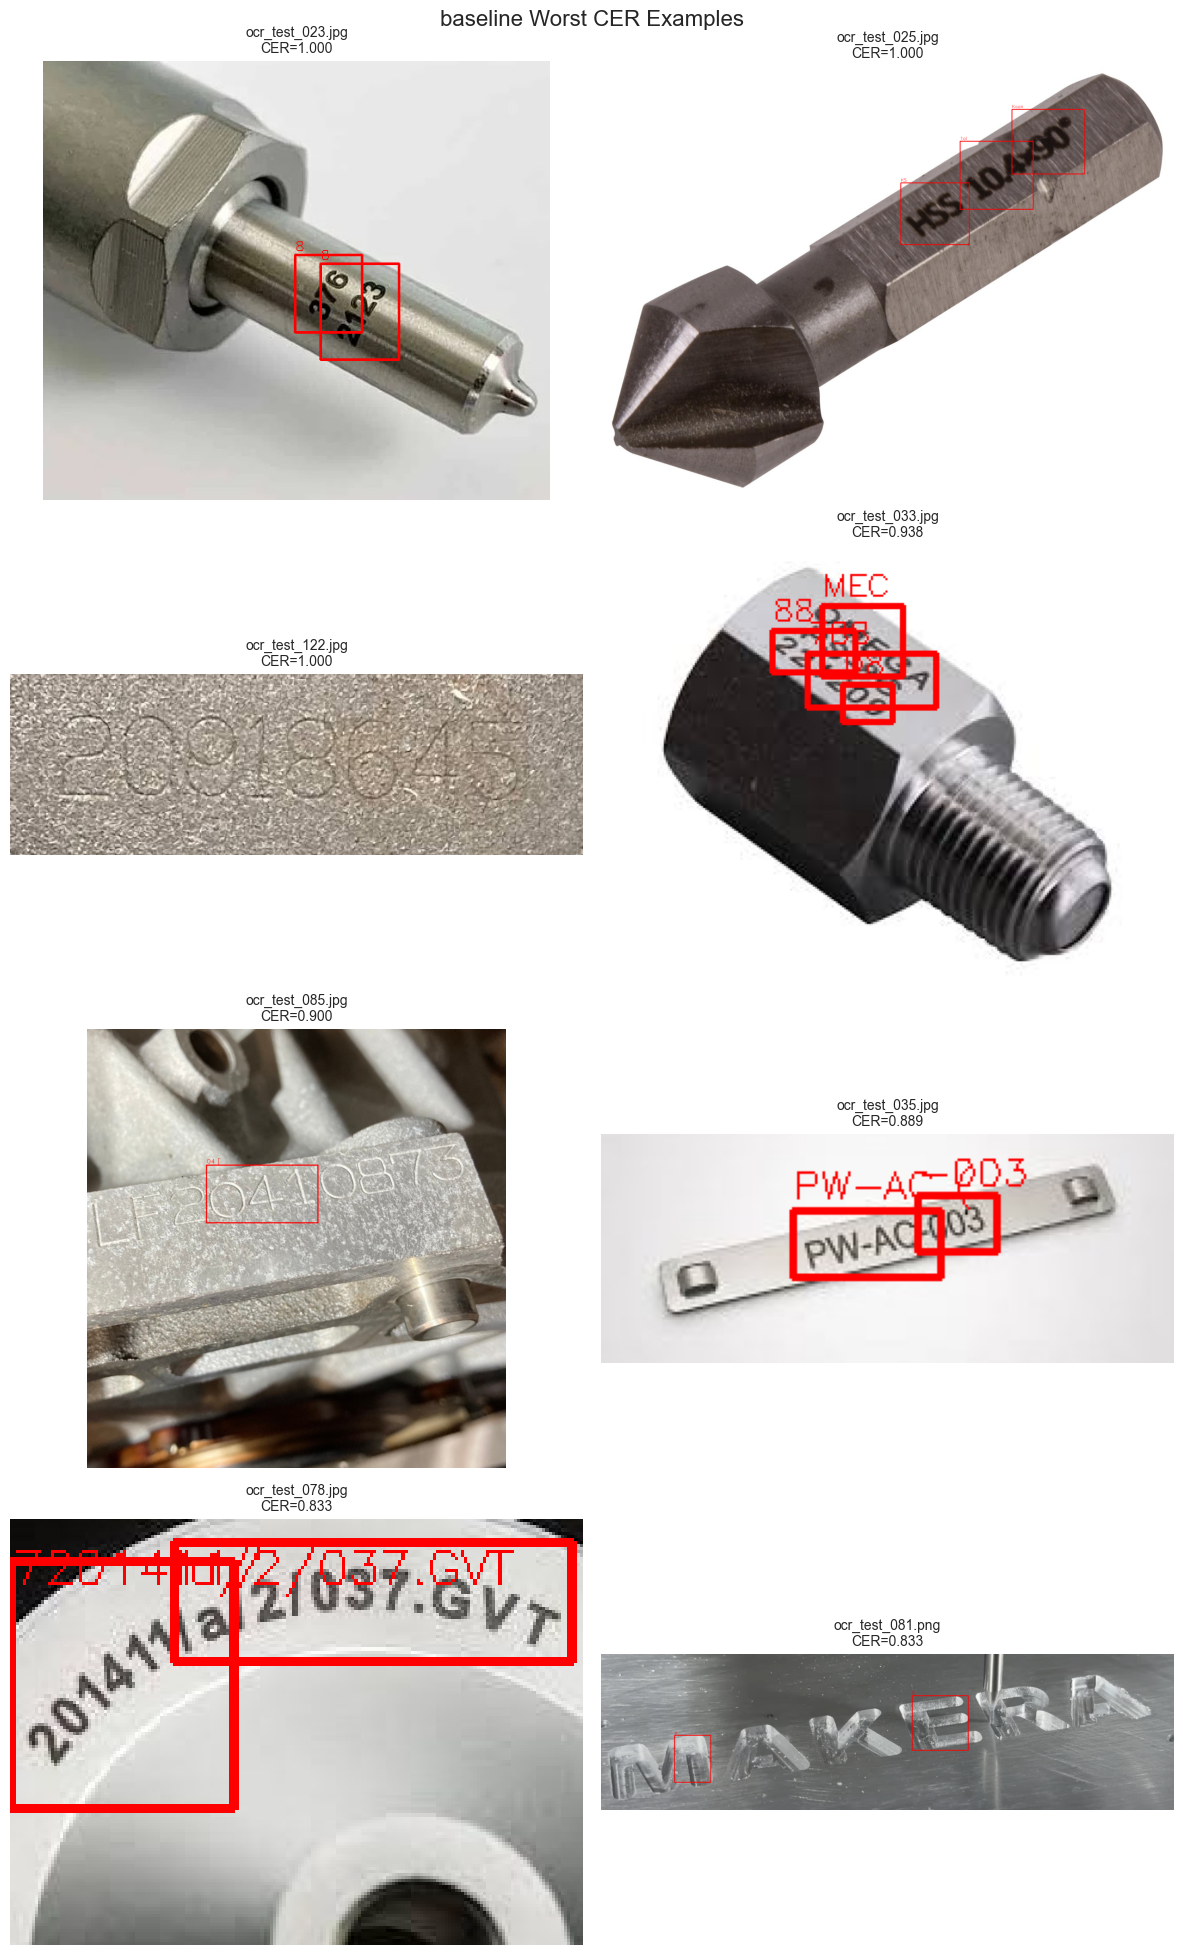

Loaded 268 OCR records


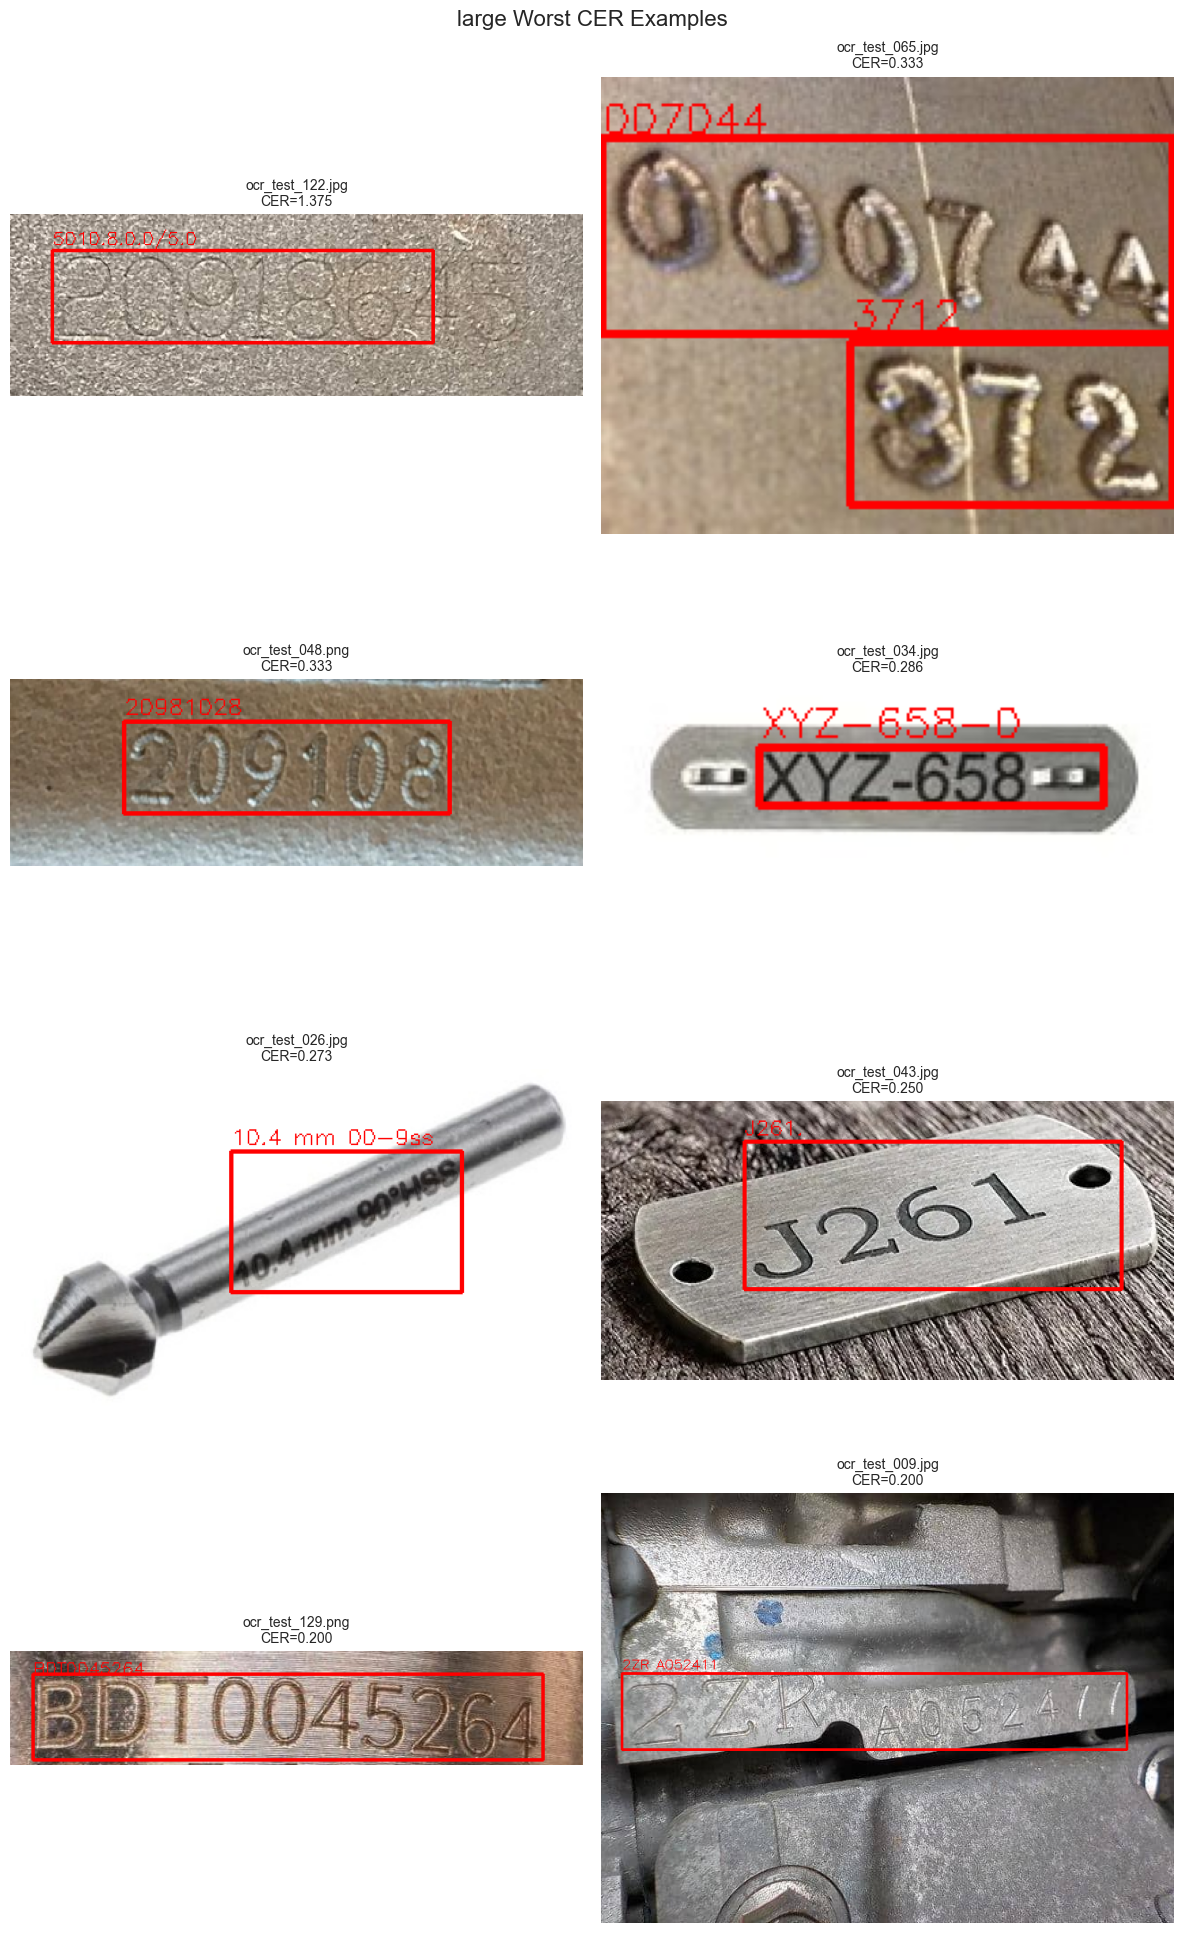

Loaded 268 OCR records


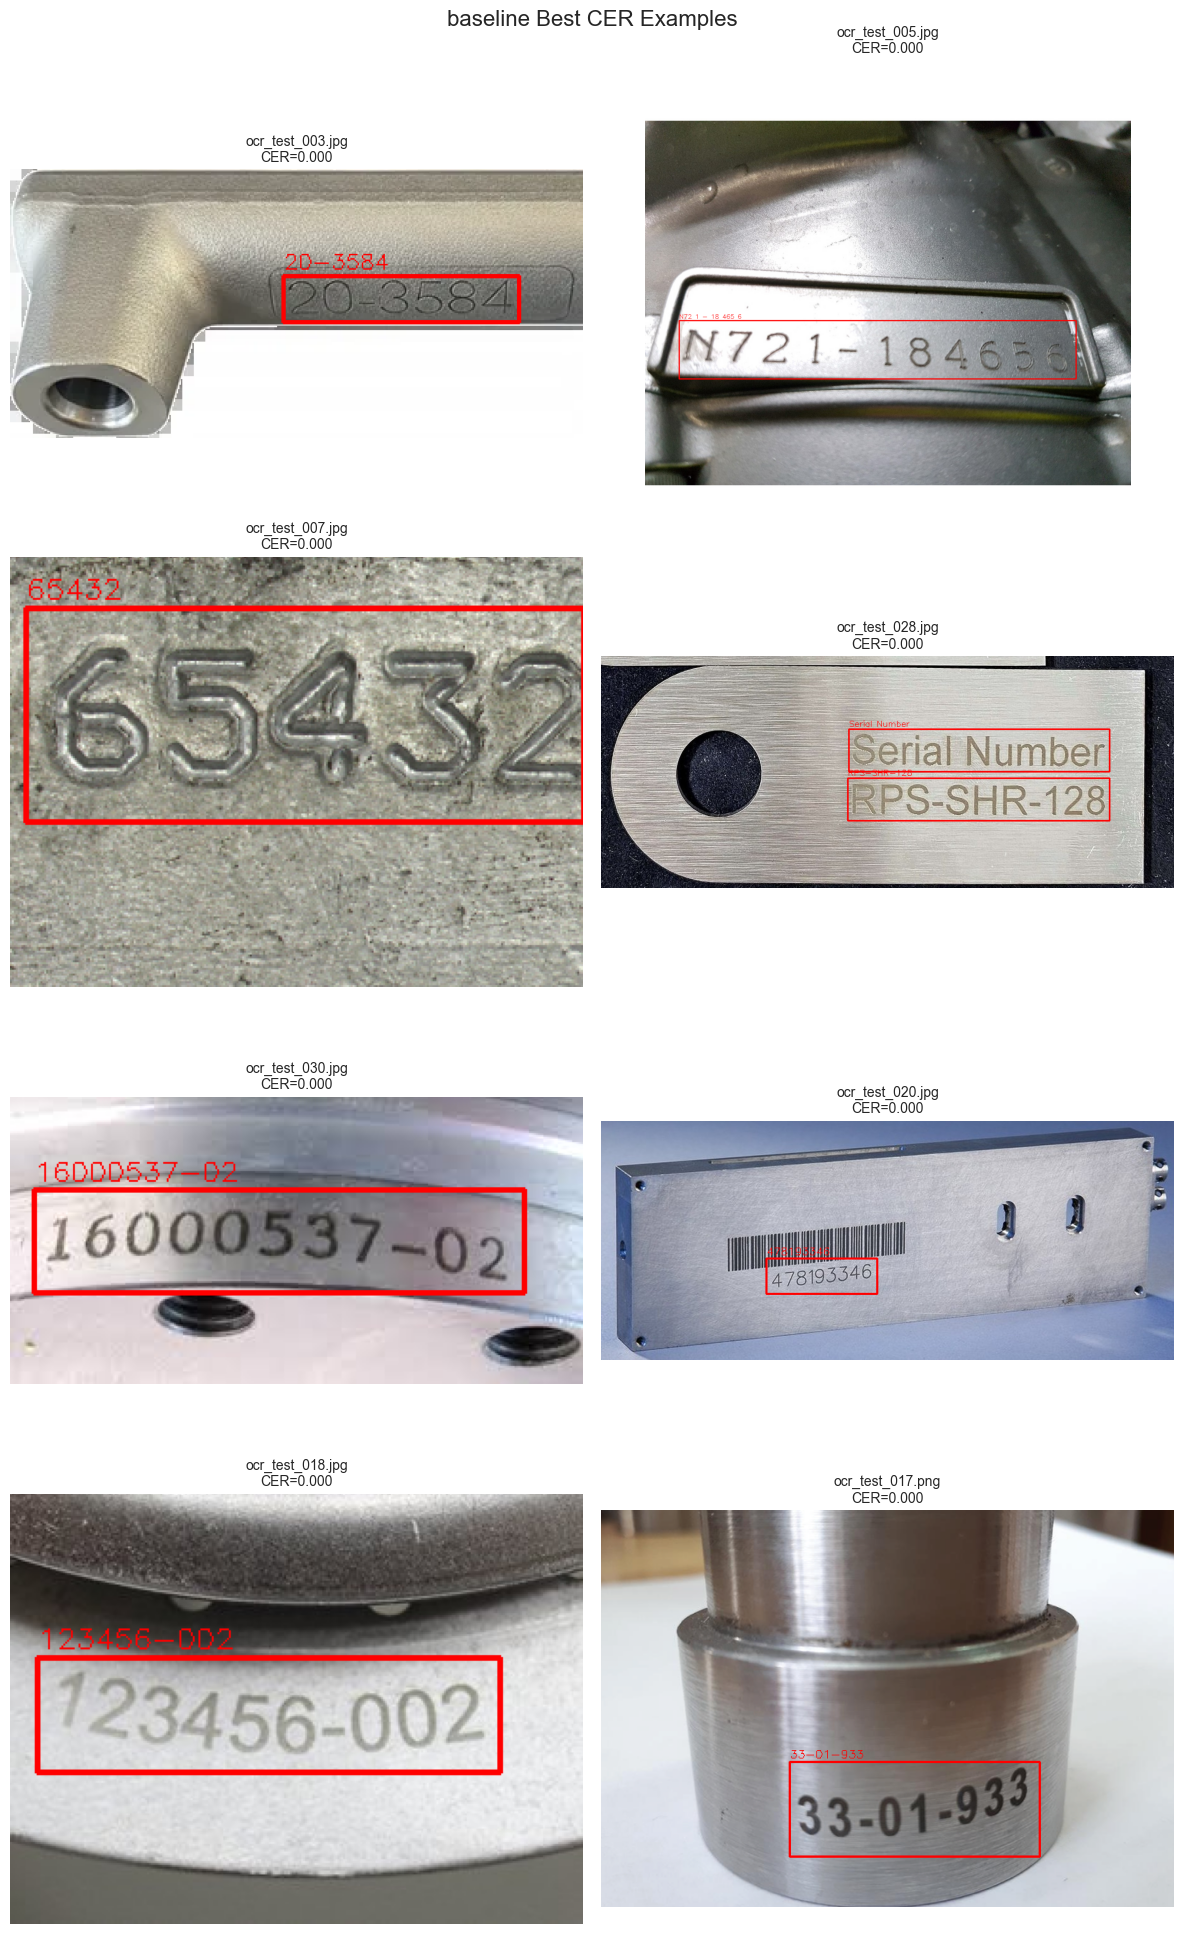

Loaded 268 OCR records


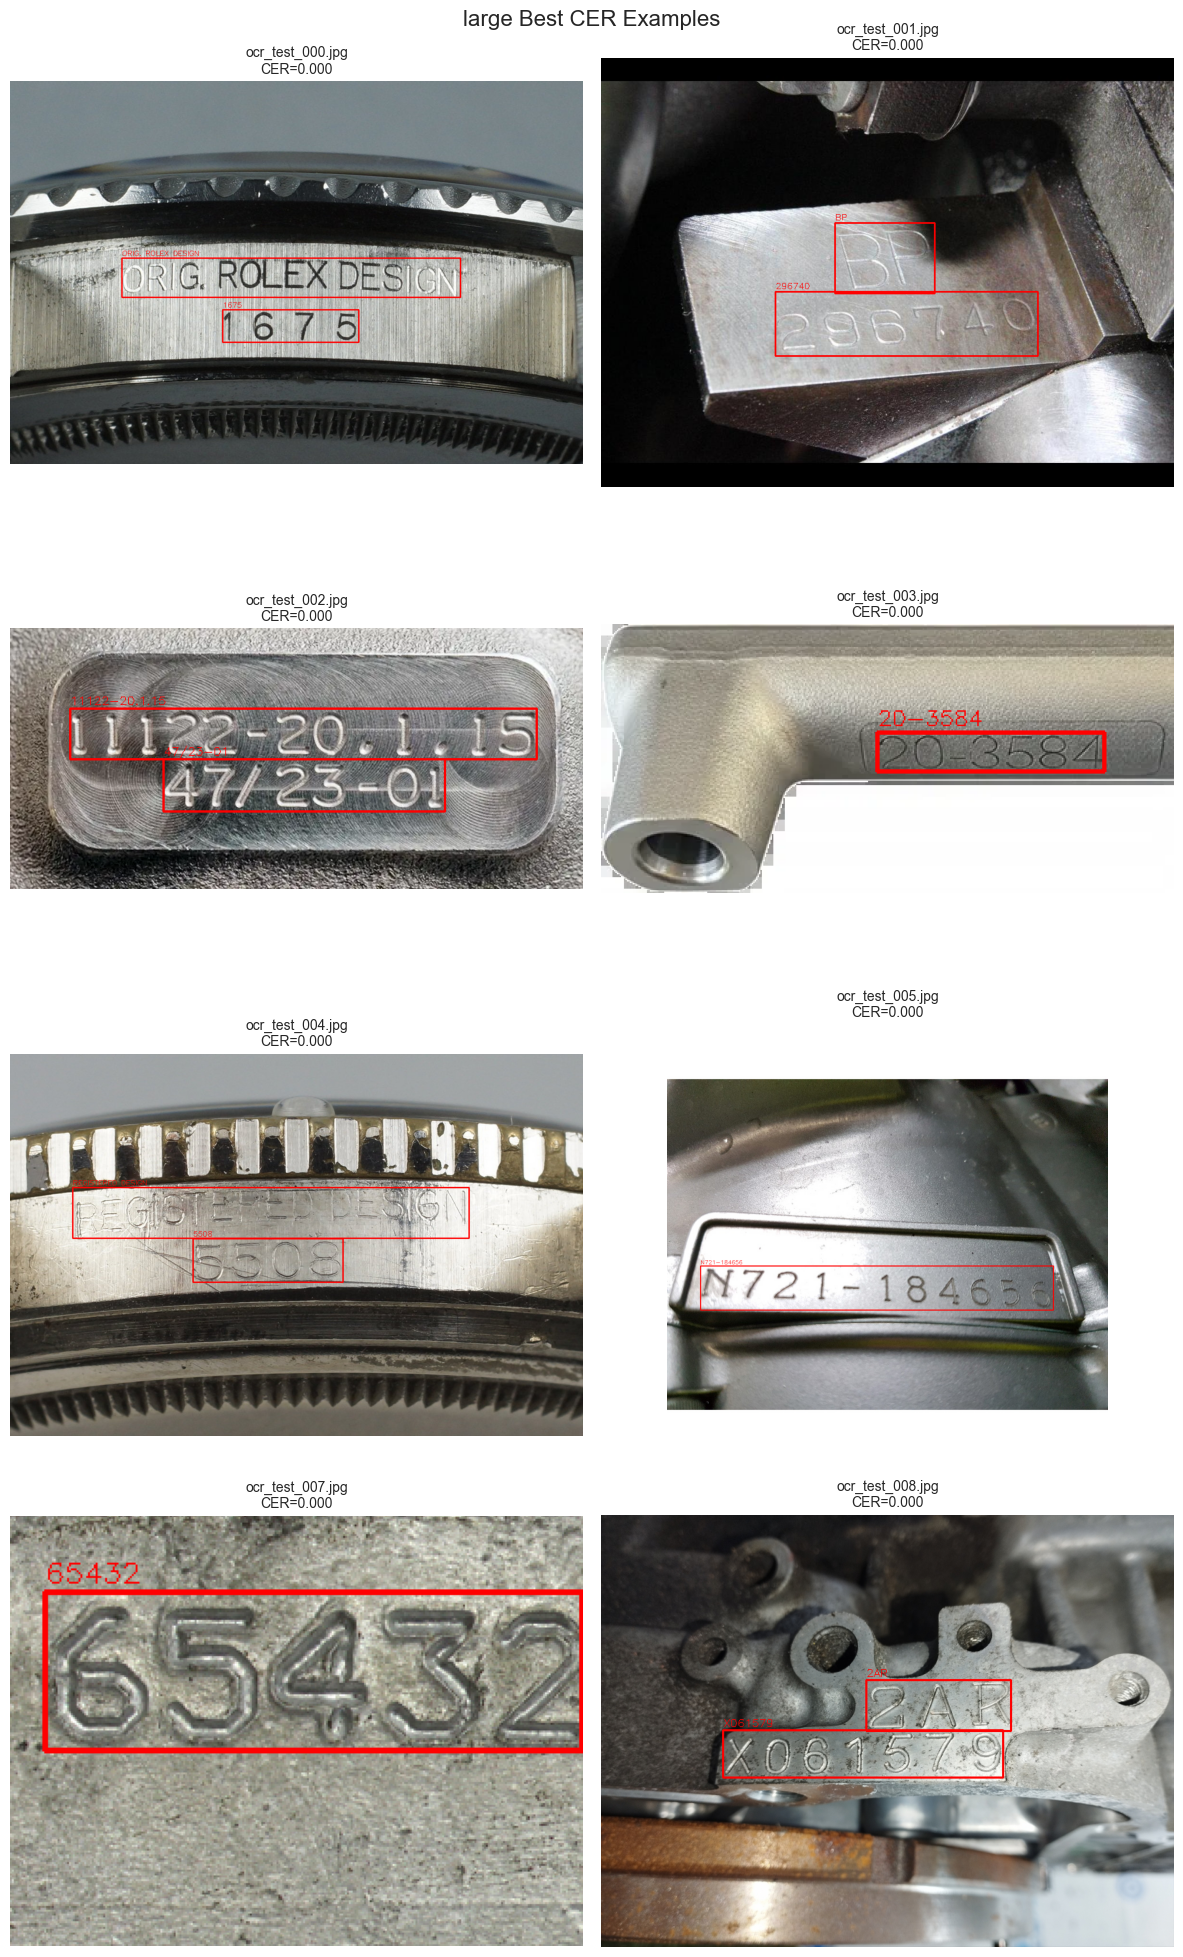

In [7]:

def get_ocr_vals(json_fp, image_dir):
    '''matches sample images to json data'''

    # initialize dictionaries 
    image_lookup, ocr_lookup = {}, {}

    # open json data
    with open(json_fp, "r", encoding="utf-8") as f:
        ocr_results = json.load(f)


    # populate image lookup with file paths
    for path in image_dir.rglob("*"):
        if path.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".tif",".tiff",}:
            image_lookup[path.stem.lower()] = path

    # loop through images in json data
    for image_entry in ocr_results["images"]:

        # base file name
        base_fn = Path(image_entry["image"]).stem.lower()

        # add json file info to ocr_lookup for each model type        
        for model_info in image_entry["models"]:

            key = (base_fn, model_info["profile"])
            ocr_lookup[key] = model_info

    print(f"Loaded {len(ocr_lookup)} OCR records")

    return ocr_lookup, image_lookup

def find_iqr_outliers(df_model):

    # determine Q1 and Q3 quartiles
    q1 = df_model["normalized_cer"].quantile(0.25)
    q3 = df_model["normalized_cer"].quantile(0.75)

    # determine inter quartile range and upper limit
    iqr = q3 - q1
    upper = q3 + (1.5 * iqr)

    # filter df for outliers (values above upper limit)
    outliers = df_model[df_model["normalized_cer"] > upper].copy()

    return outliers.sort_values("normalized_cer",ascending=False)

def draw_ocr_boxes(image,detections,draw_text=True):

    output = image.copy()

    for det in detections:
        try:
            # get bounding box coords
            x1, y1, x2, y2 = det["box_xyxy"]

            # create cv2 rectangle object
            cv2.rectangle(output,(int(x1), int(y1)),(int(x2), int(y2)),(255, 0, 0),2)

            if draw_text:
                text = det.get("text","")

                cv2.putText(
                    img = output,
                    text = text[:30],
                    org = (int(x1),max(int(y1) - 5,20)),
                    fontFace= cv2.FONT_HERSHEY_SIMPLEX,
                    fontScale=0.5,
                    color = (255, 0, 0),
                    thickness=1,
                    )

        except Exception as e:
            print(f"Bad detection: {e}")

    return output

def create_failure_gallery(df_model,profile,n=4, worst = True):

    # get formatted ocr and image data from json file and directory with sample images
    ocr_lookup, image_lookup = get_ocr_vals(json_fp, image_dir)

    if worst is True:
        outliers = df_model.sort_values("normalized_cer",ascending=False).head(n)
        title_txt = "Worst CER Examples"
    else:
        outliers = df_model.sort_values("normalized_cer",ascending=True).head(n)
        title_txt = "Best CER Examples"
    
    # determine rows and cols for plot
    cols = 2
    rows = int(np.ceil(n / cols))

    # create plot
    fig, axes = plt.subplots(rows,cols,figsize=(12, rows * 5))
    axes = np.array(axes).flatten()

    #format axes
    for ax in axes:
        ax.axis("off")

    for idx, (_, row) in enumerate(outliers.iterrows()):

        # get base file name
        base_fn = Path(str(row["image"])).stem.lower()
        
        # get full path from image lookup 
        image_path = image_lookup.get(base_fn)
        
        # continue if not found
        if image_path is None:
            continue

        # look up json data based on file name and model
        key = (base_fn,profile)
        model_data = ocr_lookup.get(key)

        # continue if model data not available
        if model_data is None:
            continue

        # open image
        img = cv2.imread(str(image_path))
        img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

        # continue if image is not available
        if img is None:
            continue

        # get info for specific image
        detections = (model_data.get("payload", {}).get("detections", []))

        # draw ocr boxes
        img = draw_ocr_boxes(img,detections,draw_text=True)
        
        # format and plot axes
        ax = axes[idx]
        ax.imshow(img)
        ax.set_title((f"{image_path.name}\nCER={row['normalized_cer']:.3f}"),fontsize=10)
        ax.axis("off")

    plt.suptitle(f"{profile} {title_txt}",fontsize=16)

    plt.tight_layout()

    plt.savefig(rf".\images\{profile}_{title_txt}_gallery.png",dpi=600)

    plt.show()

num_outliers = 8

# baseline model worst case
create_failure_gallery(df[df["Model"] == "EasyOCR"],n = num_outliers, profile="baseline")

# large model worst case
create_failure_gallery(df[df["Model"] == "Florence-2"],n = num_outliers,profile="large")

# baseline model best case
create_failure_gallery(df[df["Model"] == "EasyOCR"],n = num_outliers,profile="baseline", worst = False)

# large model best case
create_failure_gallery(df[df["Model"] == "Florence-2"],n = num_outliers,profile="large", worst = False)
